In [1]:
import tensorflow as tf

# Loading -"MNIST Data Set"
## Containing Training samples =60,000 , Testing Samples =10,000
### Tensorflow already contain MNIST dataset which can be loaded using Keras

In [2]:
mnist=tf.keras.datasets.mnist ## this is basically handwritten characters based  on 28*28 sized images of 0 to 9



## After loading the MNIST data , Divide into Train and Test datsets

In [3]:
## Unpacking the dataset into train and test dataset
(X_train,y_train),(X_test,y_test)=mnist.load_data()



11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [4]:
X_train.shape

(60000, 28, 28)

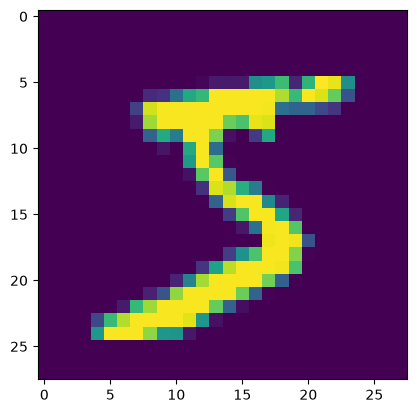

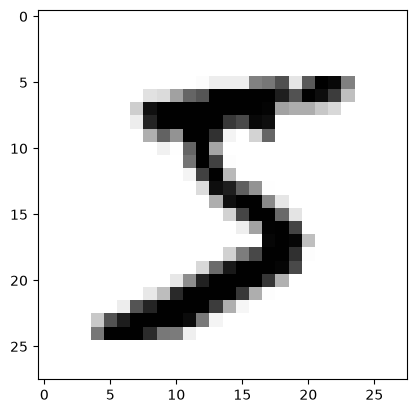

In [6]:
## just the graph , how data looks like
import matplotlib.pyplot as plt
plt.imshow(X_train[0])
plt.show()## in order to execute the graph
## however we dont know whether its color image or binary images
## so inorder to plot it change the configuration
plt.imshow(X_train[0],cmap=plt.cm.binary) # this plt.cm.binary reverses the pixel
# black becomes white and white becomes black

## Checking the values of each pixel

### Before Normalization

In [7]:
print(X_train[0])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0   0  18 219 253 253 253 253 253 198 18

### As images are in Gray level (1 channel ==> 0 to 255) , not colored(RGB)

## Normalizing the data | Pre-Processing Step

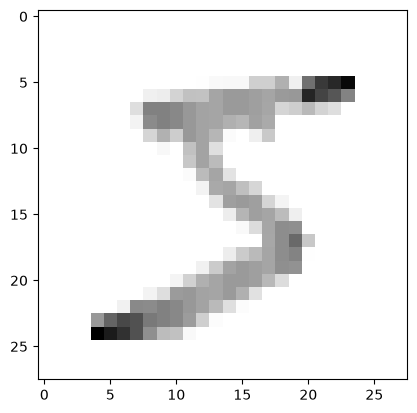

In [8]:
### You might have noticed that ,its gray image and all values varies from 0 to 255
### in order to normalize it

X_train=tf.keras.utils.normalize(X_train,axis=1)
X_test=tf.keras.utils.normalize(X_test,axis=1)
plt.imshow(X_train[0],cmap=plt.cm.binary)




### After Normalize

In [9]:
print(X_train[0]) ## all the values are between 0 and 1

[[0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.    

In [10]:
print(y_train[0]) ## just to check that we have labels inside our network

5


## Resizing image to make it suitable for apply Convulation Operation

In [11]:
import numpy as np
IMG_SIZE=28
X_trainR=np.array(X_train).reshape(-1,IMG_SIZE,IMG_SIZE,1) ### increasing  one dimesion for kernel operation
X_testR=np.array(X_test).reshape(-1,IMG_SIZE,IMG_SIZE,1) ### increasing one dimension for kernel operation
print("Training Samples dimension ",X_trainR.shape)
print("Testing Samples dimension ",X_testR.shape)



Training Samples dimension  (60000, 28, 28, 1)
Testing Samples dimension  (10000, 28, 28, 1)


## Creating a Deep Neural Network

### Training of 60,000 samples of MNIST handwritten dataset

In [13]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Dropout,Activation,Flatten,Conv2D,MaxPooling2D



In [14]:
#### Creating a neural network
model=Sequential()

#### First Convolution layer 0 1 2 3 (60000,28,28,1)
model.add(Conv2D(64,(3,3),input_shape=X_trainR.shape[1:]))### only for first convolution layer to mention input layer size
model.add(Activation("relu")) ## activation function to make  it non-linear <0 , remove, >0
model.add(MaxPooling2D(pool_size=(2,2)))## Maxpooling single value of 2*2

#### 2nd Convolution layer 
model.add(Conv2D(64,(3,3)))
model.add(Activation("relu")) ## activation function 
model.add(MaxPooling2D(pool_size=(2,2)))## Maxpooling single value of 2*2

#### 3rd Convolution layer  
model.add(Conv2D(64,(3,3)))
model.add(Activation("relu")) ## activation function 
model.add(MaxPooling2D(pool_size=(2,2)))## Maxpooling single value of 2*2

#### Fully Connected Layer
model.add(Flatten())
model.add(Dense(64))
model.add(Activation("relu"))







C:\Users\niwas\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
